# ML-Based Hospital Readmission Risk Prediction and Resource-Constrained Patient Prioritization

**Team:** Dwetta Pati (23BDS1072) · Sia Meel (23BDS1058) · Aaditya Arora (23BCE1867)
**Course:** BCSE497J – Project I · VIT Chennai

### What this notebook does
1. Loads and audits the *Diabetes 130-US Hospitals (1999–2008)* dataset.
2. Cleans the data with clinically motivated exclusions and feature engineering (ICD-9 grouping, categorical admission/discharge codes, medication summaries).
3. Splits the data **at patient level**, so the same patient never appears in both train and test (this removes the leakage present in the Review-1 version).
4. Trains and compares Logistic Regression, Random Forest and XGBoost, with hyperparameters tuned by grouped cross-validation.
5. Selects a decision threshold on out-of-fold predictions, calibrates the risk scores and explains the model with SHAP.
6. Evaluates the **core contribution**: given a fixed intervention capacity, how many true readmissions does risk-based prioritisation capture compared with random selection and a simple clinical heuristic?
7. Checks robustness across patient subgroups.
8. Translates prioritisation into costs and benefits, with a sensitivity analysis.
9. Confirms stability across five different patient-level splits, and saves the final model for the live demo (`app/app.py`).

In [1]:
import sys, json, time, warnings
sys.path.insert(0, 'src')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve, confusion_matrix,
                             precision_score, recall_score, f1_score)
from xgboost import XGBClassifier
import shap

from pipeline import *

pd.set_option('display.max_columns', 60)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})
PALETTE = {'XGBoost': '#1f4e79', 'Random Forest': '#4f9d69', 'Logistic Regression': '#c8963e',
           'Heuristic (prior inpatient visits)': '#8c564b', 'Random': '#9e9e9e', 'Oracle': '#d62728'}
FIG, TAB = 'figures/', 'tables/'

def savefig(name):
    plt.savefig(FIG + name)
    plt.show()

def savetab(df, name):
    df.to_csv(TAB + name, index=True)
    return df

print('Setup complete')

Setup complete


## 1. Data loading and audit

In [2]:
raw = load_raw('data/diabetic_data.csv')
print('Shape:', raw.shape)
print('Unique patients:', raw['patient_nbr'].nunique())
print('Patients with more than one encounter:', (raw.groupby('patient_nbr').size() > 1).sum())
raw.head()

Shape: (101766, 50)
Unique patients: 71518
Patients with more than one encounter: 16773


In [3]:
missing = (raw.isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0].round(2).to_frame('% missing')
savetab(missing, 'table_missing_values.csv')

,% missing
weight,96.86
max_glu_serum,94.75
A1Cresult,83.28
medical_specialty,49.08
payer_code,39.56
race,2.23
diag_3,1.40
diag_2,0.35
diag_1,0.02


`weight` (≈97% missing) and `payer_code` (≈40% missing, administrative rather than clinical) are dropped. `medical_specialty` is ≈49% missing, so *Missing* is kept as its own category, because whether a specialty was recorded may itself carry information.

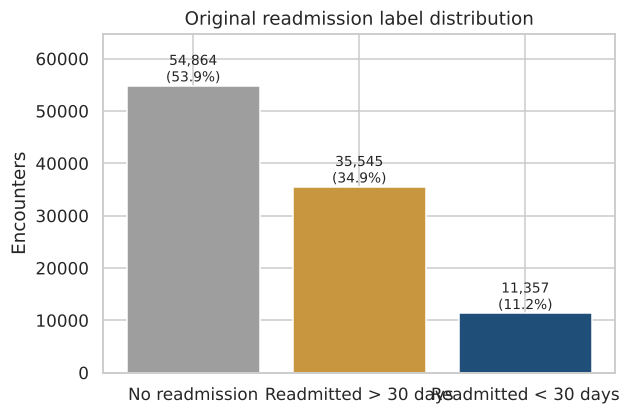

In [4]:
counts = raw['readmitted'].value_counts().reindex(['NO', '>30', '<30'])
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['No readmission', 'Readmitted > 30 days', 'Readmitted < 30 days'], counts.values,
              color=['#9e9e9e', '#c8963e', '#1f4e79'])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 800, f'{v:,}\n({v / len(raw):.1%})', ha='center', fontsize=9)
ax.set_ylabel('Encounters'); ax.set_title('Original readmission label distribution')
ax.set_ylim(0, counts.max() * 1.18)
savefig('fig01_readmission_distribution.png')

## 2. Cleaning and feature engineering

| Step | Rationale |
|---|---|
| Remove encounters discharged as *expired* (11, 19, 20, 21) or to *hospice* (13, 14) | These patients cannot be readmitted, so keeping them as negatives would bias the model. |
| Remove `Unknown/Invalid` gender | 3 records, data-entry errors. |
| Map `admission_type_id`, `admission_source_id`, `discharge_disposition_id` to named groups | These are **codes, not quantities**. Treating them as numbers (as in the Review-1 version) implies a false ordering. |
| Group `diag_1/2/3` ICD-9 codes into 9 clinical categories | Raw codes have ~700 levels each and created ~2,200 sparse one-hot columns. Grouping follows Strack et al. (2014). |
| Convert age bracket to its midpoint | Keeps the ordinal information. |
| Keep 8 common diabetes medications; summarise all 23 as *number of medication changes* and *number of diabetes medications* | The other 15 drugs are >99% "No". |
| Add `total_prior_visits` | Overall prior utilisation. |
| Target `readmit_30` = 1 if readmitted within 30 days | The clinically and financially relevant outcome (e.g. the US Hospital Readmissions Reduction Program). |

In [5]:
df, TOP_SPECIALTIES, clean_log = clean(raw, return_log=True)
flow = pd.DataFrame(clean_log, columns=['Step', 'Encounters', 'Patients']).set_index('Step')
savetab(flow, 'table_cleaning_flow.csv')

,Encounters,Patients
Step,,
Raw encounters,101766,71518
Removed expired / hospice discharges,99343,69990
Removed invalid gender,99340,69987


In [6]:
print('Modelling dataset:', df.shape)
print(f"30-day readmission rate: {df['readmit_30'].mean():.2%}")
print('Features used:', len(FEATURES), f'({len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical)')
df[FEATURES].head()

Modelling dataset: (99340, 36)
30-day readmission rate: 11.39%
Features used: 33 (14 numeric, 19 categorical)


,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,total_prior_visits,num_med_changes,num_diabetes_meds,med_change,diabetes_med,gender,race,admission_type,admission_source,discharge_to,medical_specialty,diag_1_group,diag_2_group,diag_3_group,A1Cresult,max_glu_serum,metformin,glipizide,glyburide,pioglitazone,rosiglitazone,glimepiride,repaglinide,insulin
0,5,1,41,0,1,0,0,0,1,0,0,0,0,0,Female,Caucasian,Unknown,Referral,Unknown/Other,Other,Diabetes,Missing,Missing,Not tested,Not tested,No,No,No,No,No,No,No,No
1,15,3,59,0,18,0,0,0,9,0,1,1,1,1,Female,Caucasian,Emergency,Emergency Room,Home,Missing,Other,Diabetes,Other,Not tested,Not tested,No,No,No,No,No,No,No,Up
2,25,2,11,5,13,2,0,1,6,3,0,1,0,1,Female,AfricanAmerican,Emergency,Emergency Room,Home,Missing,Other,Diabetes,Other,Not tested,Not tested,No,Steady,No,No,No,No,No,No
3,35,2,44,1,16,0,0,0,7,0,1,1,1,1,Male,Caucasian,Emergency,Emergency Room,Home,Missing,Other,Diabetes,Circulatory,Not tested,Not tested,No,No,No,No,No,No,No,Up
4,45,1,51,0,8,0,0,0,5,0,0,2,1,1,Male,Caucasian,Emergency,Emergency Room,Home,Missing,Neoplasms,Neoplasms,Diabetes,Not tested,Not tested,No,Steady,No,No,No,No,No,Steady


## 3. Exploratory data analysis

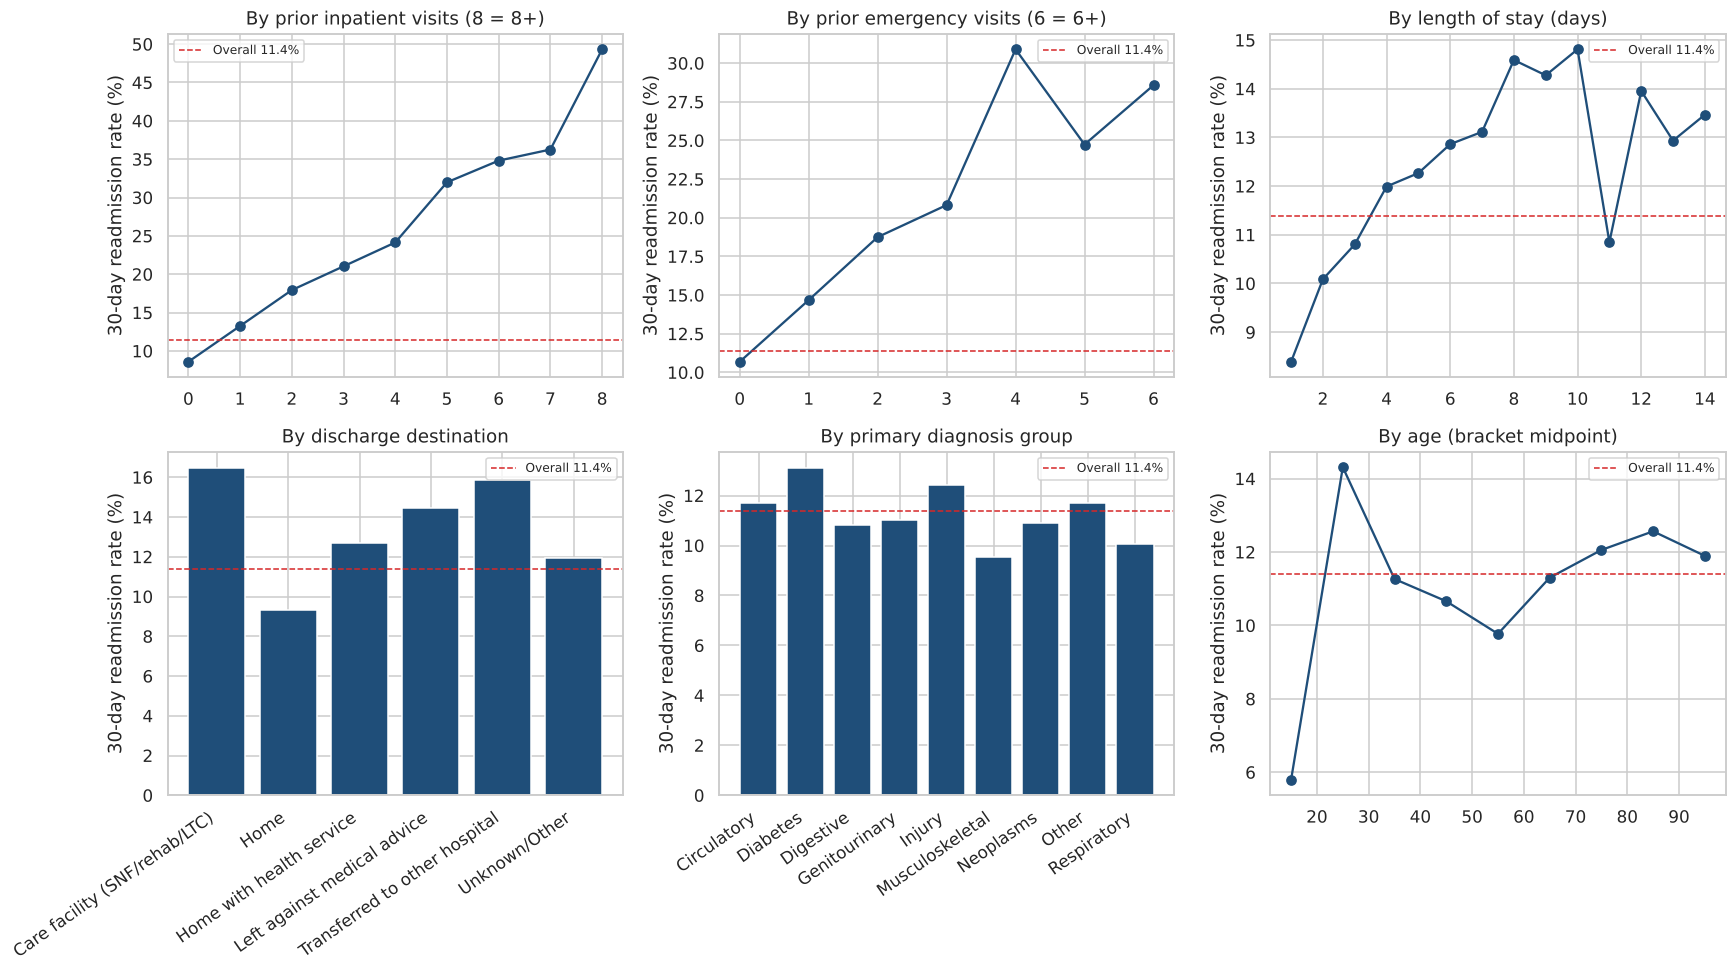

In [7]:
base = df['readmit_30'].mean()
def rate_plot(ax, col, title, order=None, kind='bar', min_n=200):
    g = df.groupby(col)['readmit_30'].agg(['mean', 'size'])
    g = g[g['size'] >= min_n]
    if order is not None:
        g = g.reindex([o for o in order if o in g.index])
    if kind == 'bar':
        ax.bar(g.index.astype(str), g['mean'] * 100, color='#1f4e79')
        ax.tick_params(axis='x', rotation=35)
        for lbl in ax.get_xticklabels(): lbl.set_ha('right')
    else:
        ax.plot(g.index, g['mean'] * 100, marker='o', color='#1f4e79')
    ax.axhline(base * 100, ls='--', color='#d62728', lw=1, label=f'Overall {base:.1%}')
    ax.set_title(title); ax.set_ylabel('30-day readmission rate (%)'); ax.legend(fontsize=8)

df['_inpatient_capped'] = df['number_inpatient'].clip(upper=8)
df['_emergency_capped'] = df['number_emergency'].clip(upper=6)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
rate_plot(axes[0, 0], '_inpatient_capped', 'By prior inpatient visits (8 = 8+)', kind='line', min_n=50)
rate_plot(axes[0, 1], '_emergency_capped', 'By prior emergency visits (6 = 6+)', kind='line', min_n=50)
rate_plot(axes[0, 2], 'time_in_hospital', 'By length of stay (days)', kind='line')
rate_plot(axes[1, 0], 'discharge_to', 'By discharge destination')
rate_plot(axes[1, 1], 'diag_1_group', 'By primary diagnosis group')
rate_plot(axes[1, 2], 'age', 'By age (bracket midpoint)', kind='line')
plt.tight_layout()
savefig('fig02_eda_readmission_rates.png')
df.drop(columns=['_inpatient_capped', '_emergency_capped'], inplace=True)

In [8]:
eda_tab = df.groupby('readmit_30')[['number_inpatient', 'number_emergency', 'number_outpatient',
                                     'time_in_hospital', 'num_medications', 'number_diagnoses',
                                     'num_lab_procedures']].mean().T.round(2)
eda_tab.columns = ['Not readmitted <30d', 'Readmitted <30d']
eda_tab['Ratio'] = (eda_tab.iloc[:, 1] / eda_tab.iloc[:, 0]).round(2)
savetab(eda_tab, 'table_eda_means.csv')

,Not readmitted <30d,Readmitted <30d,Ratio
number_inpatient,0.55,1.22,2.22
number_emergency,0.18,0.36,2.00
number_outpatient,0.36,0.44,1.22
time_in_hospital,4.33,4.77,1.10
num_medications,15.86,16.91,1.07
number_diagnoses,7.36,7.69,1.04
num_lab_procedures,42.74,44.22,1.03


**Key observations**
- Prior inpatient utilisation is by far the strongest univariate signal: the readmission rate rises from about 8% with no prior admissions to over 30% with five or more.
- Patients discharged to care facilities or transferred have higher readmission rates than those discharged home.
- Length of stay, number of diagnoses and age show weaker, roughly monotone relationships.
- These are **associations, not causal effects**.

## 4. Patient-level train/test split
The dataset has 99k encounters but only ~70k patients, and around 16k patients have several encounters. A plain row-wise split lets the model see a patient's other encounters during training and then be tested on that same patient, which inflates the scores. We therefore use `GroupShuffleSplit` on `patient_nbr` (80/20), and `StratifiedGroupKFold` for all cross-validation.

In [9]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr_idx, te_idx = next(gss.split(df, df['readmit_30'], df['patient_nbr']))
train, test = df.iloc[tr_idx].reset_index(drop=True), df.iloc[te_idx].reset_index(drop=True)
X_train, y_train, g_train = train[FEATURES], train['readmit_30'], train['patient_nbr']
X_test, y_test = test[FEATURES], test['readmit_30']

overlap = set(train['patient_nbr']) & set(test['patient_nbr'])
split_tab = pd.DataFrame({
    'Encounters': [len(train), len(test)],
    'Patients': [train['patient_nbr'].nunique(), test['patient_nbr'].nunique()],
    'Readmit <30d': [int(y_train.sum()), int(y_test.sum())],
    'Readmit rate': [f'{y_train.mean():.2%}', f'{y_test.mean():.2%}']}, index=['Train', 'Test'])
print('Patients appearing in both sets:', len(overlap))
savetab(split_tab, 'table_split.csv')

Patients appearing in both sets: 0


,Encounters,Patients,Readmit <30d,Readmit rate
Train,79567,55989,9070,11.40%
Test,19773,13998,2244,11.35%


## 5. Models
Three model families on identical features:
- **Logistic Regression**: interpretable linear baseline (standardised, L2-regularised, class-balanced).
- **Random Forest**: bagged trees, class-balanced.
- **XGBoost**: gradient-boosted trees with `scale_pos_weight` to handle the 1:7.8 class imbalance.

XGBoost hyperparameters are tuned with a small random search under 3-fold grouped CV on the training set, optimising ROC-AUC.

In [10]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

rng = np.random.default_rng(RANDOM_STATE)
space = {'max_depth': [3, 4, 5, 6], 'learning_rate': [0.02, 0.03, 0.05, 0.08],
         'n_estimators': [300, 500, 700], 'min_child_weight': [1, 5, 10, 20],
         'subsample': [0.7, 0.8, 1.0], 'colsample_bytree': [0.5, 0.7, 0.9]}
configs = [{k: rng.choice(v).item() for k, v in space.items()} for _ in range(12)]

folds = list(cv.split(X_train, y_train, g_train))
results = []
t0 = time.time()
for i, cfg in enumerate(configs):
    aucs = []
    for f_tr, f_va in folds:
        m = Pipeline([('prep', make_preprocessor()),
                      ('clf', XGBClassifier(**cfg, scale_pos_weight=spw, eval_metric='logloss',
                                            tree_method='hist', n_jobs=2, random_state=RANDOM_STATE))])
        m.fit(X_train.iloc[f_tr], y_train.iloc[f_tr])
        aucs.append(roc_auc_score(y_train.iloc[f_va], m.predict_proba(X_train.iloc[f_va])[:, 1]))
    results.append({**cfg, 'cv_auc_mean': np.mean(aucs), 'cv_auc_std': np.std(aucs)})
tuning = pd.DataFrame(results).sort_values('cv_auc_mean', ascending=False).reset_index(drop=True)
print(f'Tuning time: {time.time() - t0:.0f}s')
BEST_XGB = {k: (int(v) if k in ('max_depth', 'n_estimators', 'min_child_weight') else float(v))
            for k, v in tuning.iloc[0][list(space)].items()}
print('Best XGBoost config:', BEST_XGB)
savetab(tuning.round(4), 'table_xgb_tuning.csv').head(5)

Tuning time: 182s
Best XGBoost config: {'max_depth': 5, 'learning_rate': 0.03, 'n_estimators': 300, 'min_child_weight': 20, 'subsample': 0.8, 'colsample_bytree': 0.9}


,max_depth,learning_rate,n_estimators,min_child_weight,subsample,colsample_bytree,cv_auc_mean,cv_auc_std
0,5,0.03,300,20,0.8,0.9,0.6658,0.0048
1,4,0.02,300,10,1.0,0.5,0.6643,0.0046
2,3,0.05,300,1,0.8,0.9,0.6635,0.0046
3,4,0.02,500,1,1.0,0.9,0.6629,0.0043
4,6,0.03,300,5,1.0,0.5,0.6625,0.0031


In [11]:
def build_models():
    return {
        'Logistic Regression': Pipeline([('prep', make_preprocessor(scale=True)),
            ('clf', LogisticRegression(C=0.1, max_iter=3000, class_weight='balanced'))]),
        'Random Forest': Pipeline([('prep', make_preprocessor()),
            ('clf', RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features='sqrt',
                                           class_weight='balanced_subsample', n_jobs=-1,
                                           random_state=RANDOM_STATE))]),
        'XGBoost': Pipeline([('prep', make_preprocessor()),
            ('clf', XGBClassifier(**BEST_XGB, scale_pos_weight=spw, eval_metric='logloss',
                                  tree_method='hist', n_jobs=2, random_state=RANDOM_STATE))]),
    }

# 5-fold grouped CV on the training set: robustness estimate plus out-of-fold (OOF) predictions
cv5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof = {name: np.zeros(len(train)) for name in build_models()}
cv_rows = []
for name in build_models():
    aucs = []
    for f_tr, f_va in cv5.split(X_train, y_train, g_train):
        m = build_models()[name].fit(X_train.iloc[f_tr], y_train.iloc[f_tr])
        p = m.predict_proba(X_train.iloc[f_va])[:, 1]
        oof[name][f_va] = p
        aucs.append(roc_auc_score(y_train.iloc[f_va], p))
    cv_rows.append({'Model': name, 'CV ROC-AUC mean': np.mean(aucs), 'CV ROC-AUC std': np.std(aucs)})
cv_tab = pd.DataFrame(cv_rows).set_index('Model').round(4)
savetab(cv_tab, 'table_cv_auc.csv')

,CV ROC-AUC mean,CV ROC-AUC std
Model,,
Logistic Regression,0.6544,0.0039
Random Forest,0.6662,0.0053
XGBoost,0.6683,0.0049


In [12]:
# Fit final models on the full training set and evaluate once on the held-out test set
models, test_prob = {}, {}
for name, m in build_models().items():
    t0 = time.time()
    models[name] = m.fit(X_train, y_train)
    test_prob[name] = m.predict_proba(X_test)[:, 1]
    print(f'{name:<20} trained in {time.time() - t0:5.1f}s')

def bootstrap_ci(y, p, metric, n=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed); y = np.asarray(y); vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum() == 0: continue
        vals.append(metric(y[i], p[i]))
    return np.percentile(vals, [2.5, 97.5])

rows = []
for name, p in test_prob.items():
    lo, hi = bootstrap_ci(y_test, p, roc_auc_score)
    rows.append({'Model': name, 'ROC-AUC': roc_auc_score(y_test, p), 'ROC-AUC 95% CI': f'[{lo:.3f}, {hi:.3f}]',
                 'PR-AUC': average_precision_score(y_test, p),
                 'PR-AUC (random = prevalence)': y_test.mean()})
test_tab = pd.DataFrame(rows).set_index('Model').round(4)
savetab(test_tab, 'table_test_performance.csv')

Logistic Regression  trained in   4.0s


Random Forest        trained in  21.0s


XGBoost              trained in   5.2s


,ROC-AUC,ROC-AUC 95% CI,PR-AUC,PR-AUC (random = prevalence)
Model,,,,
Logistic Regression,0.6650,"[0.653, 0.676]",0.2130,0.1135
Random Forest,0.6751,"[0.664, 0.687]",0.2257,0.1135
XGBoost,0.6782,"[0.667, 0.690]",0.2354,0.1135


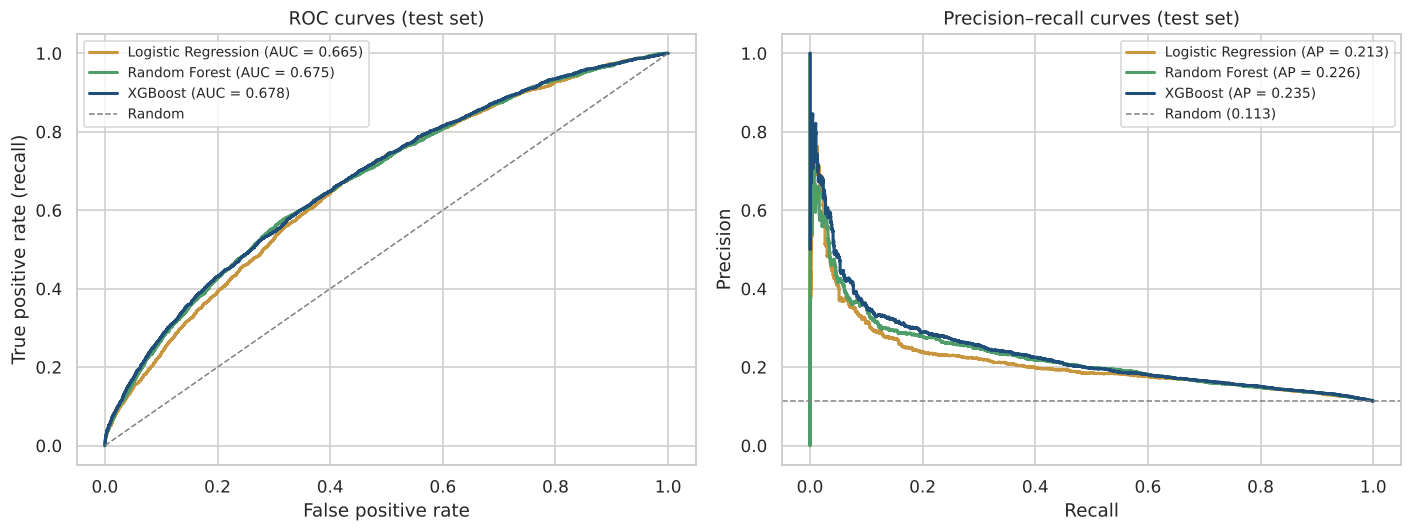

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in test_prob.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, p):.3f})', color=PALETTE[name], lw=2)
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, label=f'{name} (AP = {average_precision_score(y_test, p):.3f})', color=PALETTE[name], lw=2)
axes[0].plot([0, 1], [0, 1], ls='--', color='grey', lw=1, label='Random')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate (recall)', title='ROC curves (test set)')
axes[1].axhline(y_test.mean(), ls='--', color='grey', lw=1, label=f'Random ({y_test.mean():.3f})')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–recall curves (test set)')
for ax in axes: ax.legend(fontsize=9, loc='best')
plt.tight_layout()
savefig('fig03_roc_pr_curves.png')

**Interpretation.** XGBoost gives the best ranking performance, but the margin over Random Forest is small, and all three models land in the 0.66–0.69 ROC-AUC range. That is consistent with published work on this dataset (typically 0.64–0.70): 30-day readmission depends heavily on post-discharge factors (social support, adherence, follow-up care) that are not recorded in the encounter data. The model should be judged on how useful its **ranking** is for allocation, not on raw accuracy, which a "predict nobody" model would trivially win at ~89%.

## 6. Decision threshold
The threshold is chosen on **out-of-fold training predictions**, never on the test set. We report several operating points and choose the one that maximises F1 for the readmission class.

In [14]:
best = 'XGBoost'
ths = np.round(np.arange(0.30, 0.71, 0.05), 2)
def thr_table(y, p):
    out = []
    for t in ths:
        yp = (p >= t).astype(int)
        out.append({'Threshold': t, 'Flagged (%)': yp.mean() * 100,
                    'Recall': recall_score(y, yp), 'Precision': precision_score(y, yp, zero_division=0),
                    'F1': f1_score(y, yp)})
    return pd.DataFrame(out).set_index('Threshold').round(3)

oof_thr = thr_table(y_train, oof[best])
THRESHOLD = float(oof_thr['F1'].idxmax())
print('Threshold selected on OOF predictions (max F1):', THRESHOLD)
test_thr = thr_table(y_test, test_prob[best])
savetab(test_thr, 'table_threshold_analysis_test.csv')

Threshold selected on OOF predictions (max F1): 0.55


,Flagged (%),Recall,Precision,F1
Threshold,,,,
0.30,85.703,0.955,0.126,0.223
0.35,74.313,0.894,0.137,0.237
0.40,61.923,0.810,0.148,0.251
0.45,49.153,0.710,0.164,0.266
0.50,37.627,0.601,0.181,0.278
0.55,26.556,0.474,0.202,0.284
0.60,15.992,0.340,0.241,0.282
0.65,7.879,0.201,0.289,0.237
0.70,3.515,0.107,0.345,0.163


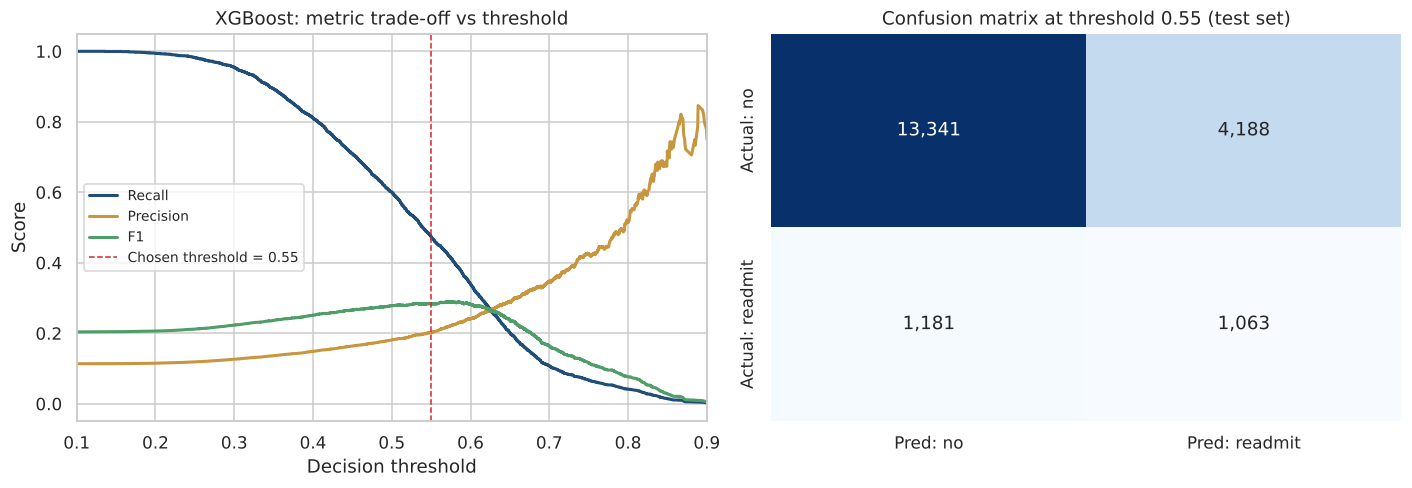

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
pr, rc, th = precision_recall_curve(y_test, test_prob[best])
axes[0].plot(th, rc[:-1], label='Recall', color='#1f4e79', lw=2)
axes[0].plot(th, pr[:-1], label='Precision', color='#c8963e', lw=2)
f1 = 2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12)
axes[0].plot(th, f1, label='F1', color='#4f9d69', lw=2)
axes[0].axvline(THRESHOLD, ls='--', color='#d62728', lw=1, label=f'Chosen threshold = {THRESHOLD}')
axes[0].set(xlabel='Decision threshold', ylabel='Score', title='XGBoost: metric trade-off vs threshold', xlim=(0.1, 0.9))
axes[0].legend(fontsize=9)
cm = confusion_matrix(y_test, (test_prob[best] >= THRESHOLD).astype(int))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['Pred: no', 'Pred: readmit'], yticklabels=['Actual: no', 'Actual: readmit'])
axes[1].set_title(f'Confusion matrix at threshold {THRESHOLD} (test set)')
plt.tight_layout()
savefig('fig04_threshold_confusion.png')

## 7. Probability calibration
With `scale_pos_weight` the raw XGBoost scores are **ranking scores, not probabilities**: they systematically overestimate risk. For decision support we want a score such that "0.3" really means "about 30% chance". We fit an isotonic regression on the out-of-fold predictions, so no test data is used, and apply it to the test scores. Isotonic calibration is monotone (non-decreasing), so it preserves the ordering of patients apart from creating some ties. We therefore **rank patients by the raw score** and use the calibrated value only to communicate risk, which leaves the prioritisation results unaffected.

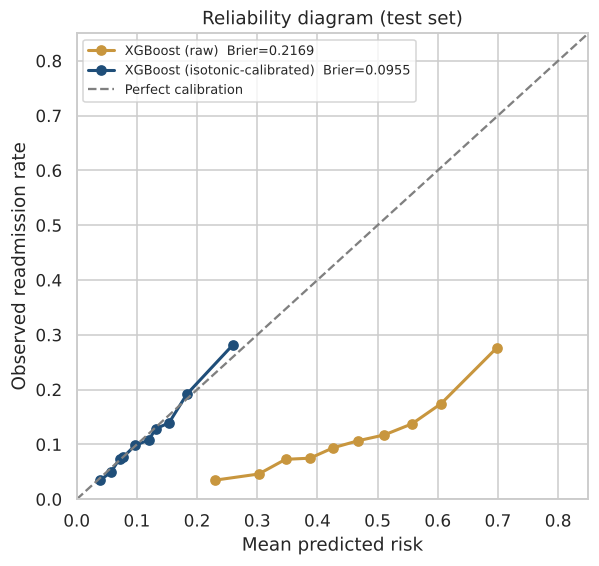

ROC-AUC raw vs calibrated: 0.6782 0.6777


In [16]:
calibrator = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(oof[best], y_train)
p_raw, p_cal = test_prob[best], calibrator.predict(test_prob[best])

fig, ax = plt.subplots(figsize=(6, 5.5))
for p, lbl, c in [(p_raw, 'XGBoost (raw)', '#c8963e'), (p_cal, 'XGBoost (isotonic-calibrated)', '#1f4e79')]:
    fr, mp = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    ax.plot(mp, fr, marker='o', lw=2, color=c, label=f'{lbl}  Brier={brier_score_loss(y_test, p):.4f}')
ax.plot([0, 1], [0, 1], ls='--', color='grey', label='Perfect calibration')
ax.set(xlabel='Mean predicted risk', ylabel='Observed readmission rate', title='Reliability diagram (test set)',
       xlim=(0, 0.85), ylim=(0, 0.85))
ax.legend(fontsize=8.5)
savefig('fig05_calibration.png')
print('ROC-AUC raw vs calibrated:', round(roc_auc_score(y_test, p_raw), 4), round(roc_auc_score(y_test, p_cal), 4))

## 8. Explainability (SHAP)
SHAP values break each prediction down into per-feature contributions. One-hot columns belonging to the same original feature are summed, so the importance is reported per *clinical* feature.

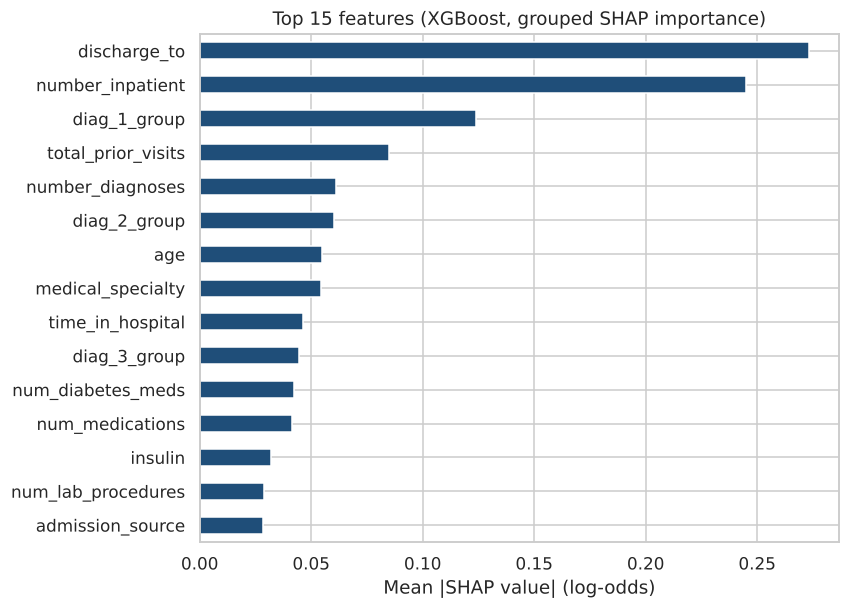

,Mean |SHAP|
discharge_to,0.2731
number_inpatient,0.2448
diag_1_group,0.1237
total_prior_visits,0.0848
number_diagnoses,0.0610
diag_2_group,0.0602
age,0.0547
medical_specialty,0.0543
time_in_hospital,0.0461
diag_3_group,0.0446


In [17]:
prep = models[best].named_steps['prep']
xgb_clf = models[best].named_steps['clf']
feat_names = prep.get_feature_names_out()
sample = X_test.sample(3000, random_state=RANDOM_STATE)
Xs = pd.DataFrame(prep.transform(sample), columns=feat_names)
explainer = shap.TreeExplainer(xgb_clf)
sv = explainer.shap_values(Xs)

def original_feature(col):
    col = col.split('__', 1)[1]
    for f in sorted(CATEGORICAL_FEATURES, key=len, reverse=True):
        if col.startswith(f + '_'):
            return f
    return col
orig = [original_feature(c) for c in feat_names]
imp = (pd.DataFrame(np.abs(sv), columns=orig).T.groupby(level=0).sum().T.mean()
       .sort_values(ascending=False))
imp_tab = imp.head(15).round(4).to_frame('Mean |SHAP|')
fig, ax = plt.subplots(figsize=(7.5, 6))
imp.head(15)[::-1].plot.barh(ax=ax, color='#1f4e79')
ax.set(xlabel='Mean |SHAP value| (log-odds)', title='Top 15 features (XGBoost, grouped SHAP importance)')
savefig('fig06_shap_importance.png')
savetab(imp_tab, 'table_feature_importance.csv')

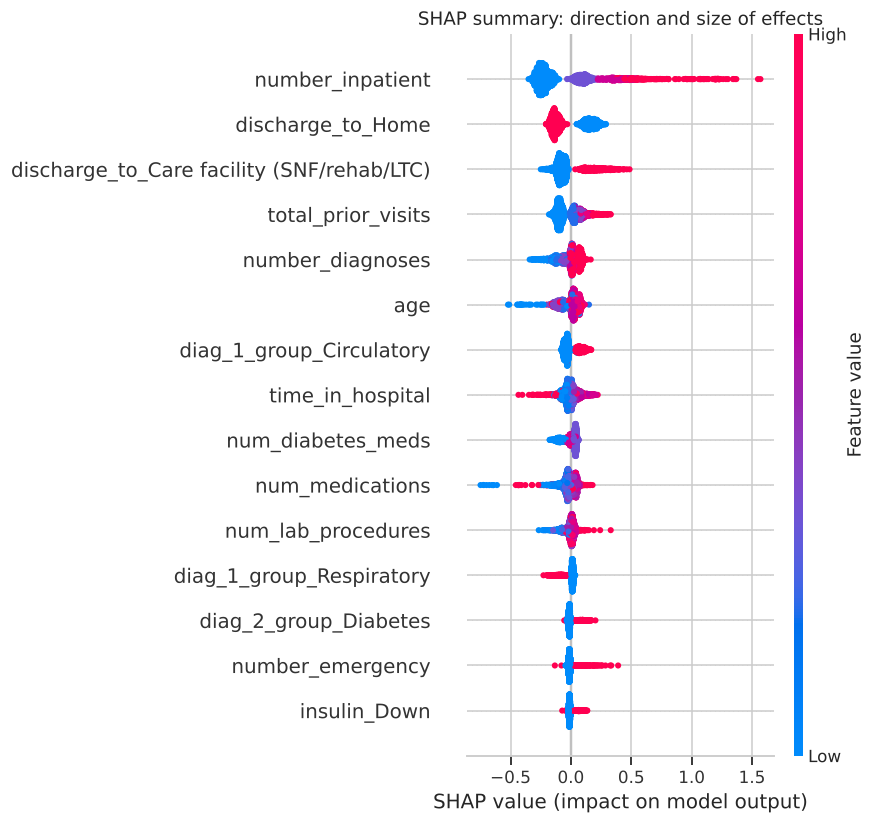

In [18]:
plt.figure()
shap.summary_plot(sv, Xs, feature_names=[c.split('__', 1)[1] for c in feat_names], max_display=15, show=False)
plt.title('SHAP summary: direction and size of effects')
savefig('fig07_shap_beeswarm.png')

**Reading the SHAP results.** Two features dominate: **discharge destination** (being discharged to a care facility or transferred raises risk, going home lowers it) and **prior inpatient visits** (each additional admission in the previous year pushes risk up). The primary diagnosis group, overall prior utilisation, number of diagnoses and age follow. These patterns are clinically plausible and agree with the EDA, which gives some confidence that the model is learning real signal rather than artefacts.

## 9. Core contribution: resource-constrained prioritisation
A hospital can follow up intensively (phone call, medication review, early clinic visit) with only a limited share of discharged patients. For each **capacity level** (5–30% of patients) we compare how many true 30-day readmissions fall inside the selected group under:
- **Random selection**: 1,000 seeded runs, reporting the mean and 95% interval.
- **Clinical heuristic**: rank by prior inpatient visits (ties broken by emergency visits), the obvious rule-of-thumb a hospital might use without ML.
- **Logistic Regression** and **XGBoost** risk ranking.
- **Oracle**: perfect knowledge, the upper bound.

"Captured" means the selected patient *was* readmitted. We have no intervention outcome data, so this does **not** mean the readmission was prevented.

In [19]:
heuristic = (X_test['number_inpatient'] * 1000 + X_test['number_emergency'] * 10 + X_test['number_outpatient']).values
capacities = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
total_pos = int(y_test.sum())
rows = []
for cap in capacities:
    rnd = random_capture(y_test, cap, n_runs=1000)
    xgb_c, k = top_k_capture(y_test, test_prob['XGBoost'], cap)
    lr_c, _ = top_k_capture(y_test, test_prob['Logistic Regression'], cap)
    heu_c, _ = top_k_capture(y_test, heuristic, cap)
    rows.append({'Capacity': f'{int(cap * 100)}%', 'Patients selected': k,
                 'Random (mean)': rnd.mean(), 'Random 95% interval': f'[{np.percentile(rnd, 2.5):.0f}, {np.percentile(rnd, 97.5):.0f}]',
                 'Heuristic': heu_c, 'Logistic Regression': lr_c, 'XGBoost': xgb_c,
                 'Oracle': min(k, total_pos),
                 'XGBoost lift vs random': xgb_c / rnd.mean(),
                 'XGBoost gain vs heuristic (%)': (xgb_c - heu_c) / heu_c * 100,
                 'XGBoost share of all readmissions (%)': xgb_c / total_pos * 100,
                 'p(random >= XGBoost)': (rnd >= xgb_c).mean()})
prio = pd.DataFrame(rows).set_index('Capacity').round(2)
print('Total true readmissions in the test set:', total_pos)
savetab(prio, 'table_prioritisation.csv')

Total true readmissions in the test set: 2244


,Patients selected,Random (mean),Random 95% interval,Heuristic,Logistic Regression,XGBoost,Oracle,XGBoost lift vs random,XGBoost gain vs heuristic (%),XGBoost share of all readmissions (%),p(random >= XGBoost)
Capacity,,,,,,,,,,,
5%,989,112.04,"[93, 131]",304,284,319,989,2.85,4.93,14.22,0.0
10%,1977,224.20,"[198, 251]",496,464,546,1977,2.44,10.08,24.33,0.0
15%,2966,335.71,"[304, 370]",669,662,723,2244,2.15,8.07,32.22,0.0
20%,3955,449.37,"[417, 482]",796,817,891,2244,1.98,11.93,39.71,0.0
25%,4943,561.66,"[524, 601]",935,966,1021,2244,1.82,9.20,45.50,0.0
30%,5932,673.12,"[633, 712]",1057,1096,1163,2244,1.73,10.03,51.83,0.0


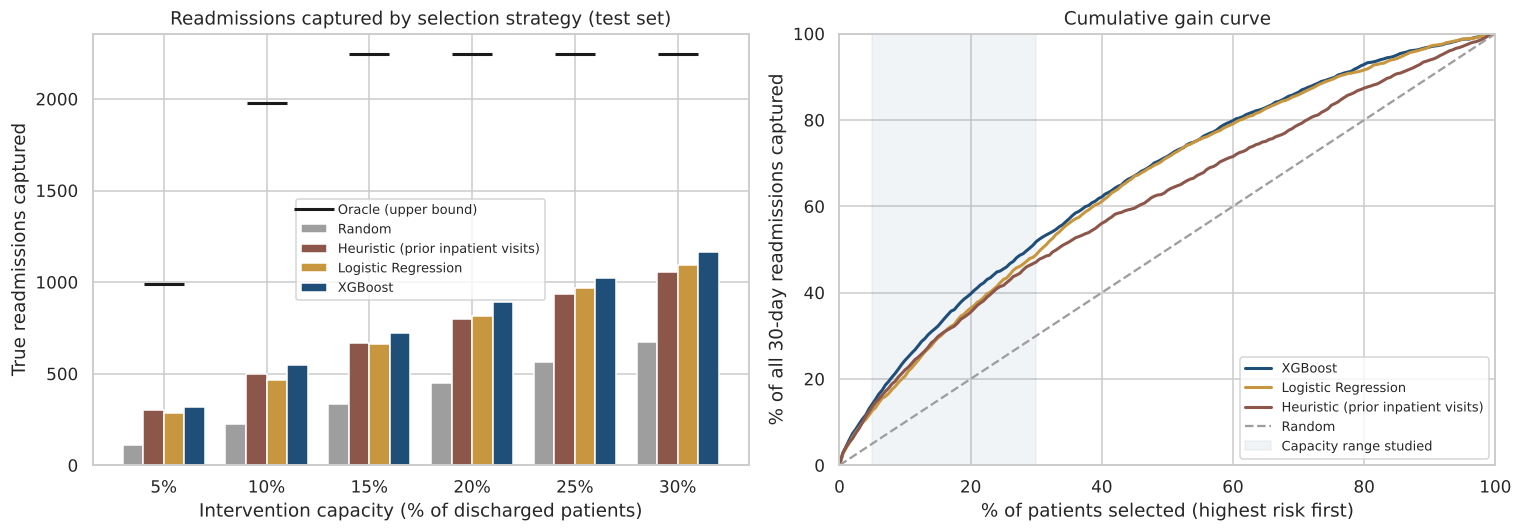

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(capacities)); w = 0.2
cols = ['Random (mean)', 'Heuristic', 'Logistic Regression', 'XGBoost']
names = ['Random', 'Heuristic (prior inpatient visits)', 'Logistic Regression', 'XGBoost']
for i, (c, n) in enumerate(zip(cols, names)):
    axes[0].bar(x + (i - 1.5) * w, prio[c], w, label=n, color=PALETTE[n])
axes[0].plot(x, prio['Oracle'], 'k_', markersize=26, mew=2, label='Oracle (upper bound)')
axes[0].set_xticks(x, prio.index)
axes[0].set(xlabel='Intervention capacity (% of discharged patients)', ylabel='True readmissions captured',
            title='Readmissions captured by selection strategy (test set)')
axes[0].legend(fontsize=8.5)

# Cumulative gain curve
fracs = np.linspace(0, 1, 201)
def gain(scores):
    order = np.argsort(-scores, kind='stable'); cum = np.cumsum(y_test.values[order])
    return [0] + [cum[max(int(f * len(order)) - 1, 0)] / total_pos for f in fracs[1:]]
for n, s in [('XGBoost', test_prob['XGBoost']), ('Logistic Regression', test_prob['Logistic Regression']),
             ('Heuristic (prior inpatient visits)', heuristic)]:
    axes[1].plot(fracs * 100, np.array(gain(s)) * 100, lw=2, color=PALETTE[n], label=n)
axes[1].plot([0, 100], [0, 100], ls='--', color=PALETTE['Random'], label='Random')
axes[1].axvspan(5, 30, color='#1f4e79', alpha=0.06, label='Capacity range studied')
axes[1].set(xlabel='% of patients selected (highest risk first)', ylabel='% of all 30-day readmissions captured',
            title='Cumulative gain curve', xlim=(0, 100), ylim=(0, 100))
axes[1].legend(fontsize=8.5, loc='lower right')
plt.tight_layout()
savefig('fig08_prioritisation.png')

In [21]:
r10 = prio.loc['10%']
print(f"At 10% capacity ({int(r10['Patients selected'])} patients): XGBoost captures {int(r10['XGBoost'])} readmissions "
      f"vs {r10['Random (mean)']:.0f} for random selection ({r10['XGBoost lift vs random']:.2f}x lift) "
      f"and {int(r10['Heuristic'])} for the prior-inpatient heuristic (+{r10['XGBoost gain vs heuristic (%)']:.1f}%).")
print(f"In 1,000 random draws, a random selection never matched XGBoost (p = {r10['p(random >= XGBoost)']}).")

At 10% capacity (1977 patients): XGBoost captures 546 readmissions vs 224 for random selection (2.44x lift) and 496 for the prior-inpatient heuristic (+10.1%).
In 1,000 random draws, a random selection never matched XGBoost (p = 0.0).


## 10. Subgroup robustness
Checks whether the model's ranking quality holds up across demographic groups. A large gap would be a fairness concern before any real deployment.

In [22]:
test_eval = test.copy(); test_eval['p'] = test_prob[best]
thr10 = np.quantile(test_eval['p'], 0.90)  # global top-10% cut-off
test_eval['age_band'] = pd.cut(test_eval['age'], [0, 40, 60, 80, 100], labels=['<40', '40-59', '60-79', '80+'])
sg_rows = []
for col in ['gender', 'age_band', 'race']:
    for grp, d in test_eval.groupby(col, observed=True):
        if len(d) < 300 or d['readmit_30'].sum() < 30: continue
        sel = d['p'] >= thr10
        sg_rows.append({'Attribute': col, 'Group': grp, 'Encounters': len(d),
                        'Readmit rate (%)': d['readmit_30'].mean() * 100,
                        'ROC-AUC': roc_auc_score(d['readmit_30'], d['p']),
                        'Selected at 10% capacity (%)': sel.mean() * 100,
                        'Readmissions captured (%)': d.loc[sel, 'readmit_30'].sum() / d['readmit_30'].sum() * 100})
subgroups = pd.DataFrame(sg_rows).set_index(['Attribute', 'Group']).round(3)
savetab(subgroups, 'table_subgroups.csv')

Encounters  Readmit rate (%)  ROC-AUC  \
Attribute Group                                                    
gender    Female                10726            11.449    0.686   
          Male                   9047            11.230    0.669   
age_band  <40                    1289            12.180    0.784   
          40-59                  5376            10.417    0.713   
          60-79                  9277            11.426    0.667   
          80+                    3831            12.190    0.595   
race      AfricanAmerican        3697            10.793    0.666   
          Caucasian             14813            11.719    0.677   
          Hispanic                398             9.045    0.778   
          Other                   302            10.265    0.701   
          Unknown                 447             7.159    0.658   

                           Selected at 10% capacity (%)  \
Attribute Group                                           
gender    Female                                 10.311   
          Male                                    9.639   
age_band  <40                                    14.973   
          40-59                                   8.705   
          60-79                                  10.262   
          80+                                     9.528   
race      AfricanAmerican                        10.955   
          Caucasian                              10.126   
          Hispanic                                9.548   
          Other                                   4.636   
          Unknown                                 3.803   

                           Readmissions captured (%)  
Attribute Group                                       
gender    Female                              24.919  
          Male                                23.622  
age_band  <40                                 45.223  
          40-59                               26.786  
          60-79                               22.358  
          80+                                 18.844  
race      AfricanAmerican                     21.303  
          Caucasian                           25.115  
          Hispanic                            41.667  
          Other                               19.355  
          Unknown                              9.375

Performance is very similar for **female and male** patients (AUC 0.686 vs 0.669). Across **age**, discrimination falls steadily with age, and is weakest for patients aged **80+ (AUC ≈ 0.60)**, where only about 19% of readmissions are captured at 10% capacity compared with 22–27% in other groups. Older patients' readmissions are likely driven by frailty and social factors that the dataset does not record. Results for the smaller race groups (Hispanic, Other, Unknown; fewer than 450 encounters each) are too noisy to interpret. This is an honest limitation: before any clinical use, the elderly subgroup would need extra features or a dedicated model, plus a formal fairness audit (equal opportunity, within-group calibration).

## 11. Cost–benefit analysis of prioritisation
Capturing readmissions only matters if acting on them is worth the cost. We put a simple, transparent economic model on top of the prioritisation results:

$$\text{Net benefit} = \underbrace{C_{\text{captured}} \times e \times \text{Cost}_{\text{readmission}}}_{\text{readmission costs avoided}} \; - \; \underbrace{k \times \text{Cost}_{\text{follow-up}}}_{\text{programme cost}}$$

| Parameter | Base value | Range tested | Source / rationale |
|---|---|---|---|
| Cost of one readmission | US \$15,200 | fixed | Average readmission cost, US 2018 (Weiss & Jiang, HCUP Statistical Brief #278, 2021) |
| Follow-up cost per patient, `Cost_follow-up` | US \$300 | \$100 – \$1,000 | Typical transitional-care package (phone calls, medication review, early clinic visit) |
| Intervention effectiveness, `e` | 20% | 10% – 30% | Relative reduction in 30-day readmissions from transitional-care RCTs (Leppin et al., 2014) |

The values are **illustrative assumptions**, not outcomes measured in this dataset, which is why every conclusion is checked across the whole sensitivity range. Results are reported per 1,000 discharged patients so they scale to any hospital.

In [23]:
READMIT_COST, FOLLOWUP_COST, EFFECT = 15200, 300, 0.20
N = len(y_test)

def capture_at(scores, cap):
    return top_k_capture(y_test, scores, cap)[0]

strategies = {'Random': None, 'Heuristic (prior inpatient visits)': heuristic, 'XGBoost': test_prob['XGBoost']}
rows = []
for cap in capacities:
    k = int(round(N * cap))
    for s, sc in strategies.items():
        captured = y_test.mean() * k if sc is None else capture_at(sc, cap)
        prevented = captured * EFFECT
        net = prevented * READMIT_COST - k * FOLLOWUP_COST
        rows.append({'Capacity': f'{int(cap * 100)}%', 'Strategy': s,
                     'Readmissions prevented per 1,000 discharges': prevented / N * 1000,
                     'Net benefit per 1,000 discharges (US$)': net / N * 1000,
                     'Number needed to follow up': k / prevented})
cb = pd.DataFrame(rows)
cb_tab = cb.pivot(index='Capacity', columns='Strategy', values='Net benefit per 1,000 discharges (US$)')
cb_tab = cb_tab[list(strategies)].reindex([f'{int(c * 100)}%' for c in capacities]).round(0)
nnt = cb.pivot(index='Capacity', columns='Strategy', values='Number needed to follow up')[list(strategies)]
nnt = nnt.reindex(cb_tab.index).round(1)
nnt.columns = [f'NNF: {c}' for c in nnt.columns]
savetab(pd.concat([cb_tab, nnt], axis=1), 'table_cost_benefit.csv')

,Random,Heuristic (prior inpatient visits),XGBoost,NNF: Random,NNF: Heuristic (prior inpatient visits),NNF: XGBoost
Capacity,,,,,,
5%,2251.0,31733.0,34039.0,44.1,16.3,15.5
10%,4500.0,46262.0,53949.0,44.1,19.9,18.1
15%,6751.0,57855.0,66157.0,44.1,22.2,20.5
20%,9002.0,62375.0,76981.0,44.1,24.8,22.2
25%,11250.0,68755.0,81977.0,44.1,26.4,24.2
30%,13501.0,72507.0,88804.0,44.1,28.1,25.5


*NNF (number needed to follow up)* is the number of patients who must receive the intervention to prevent one readmission. Lower is better.

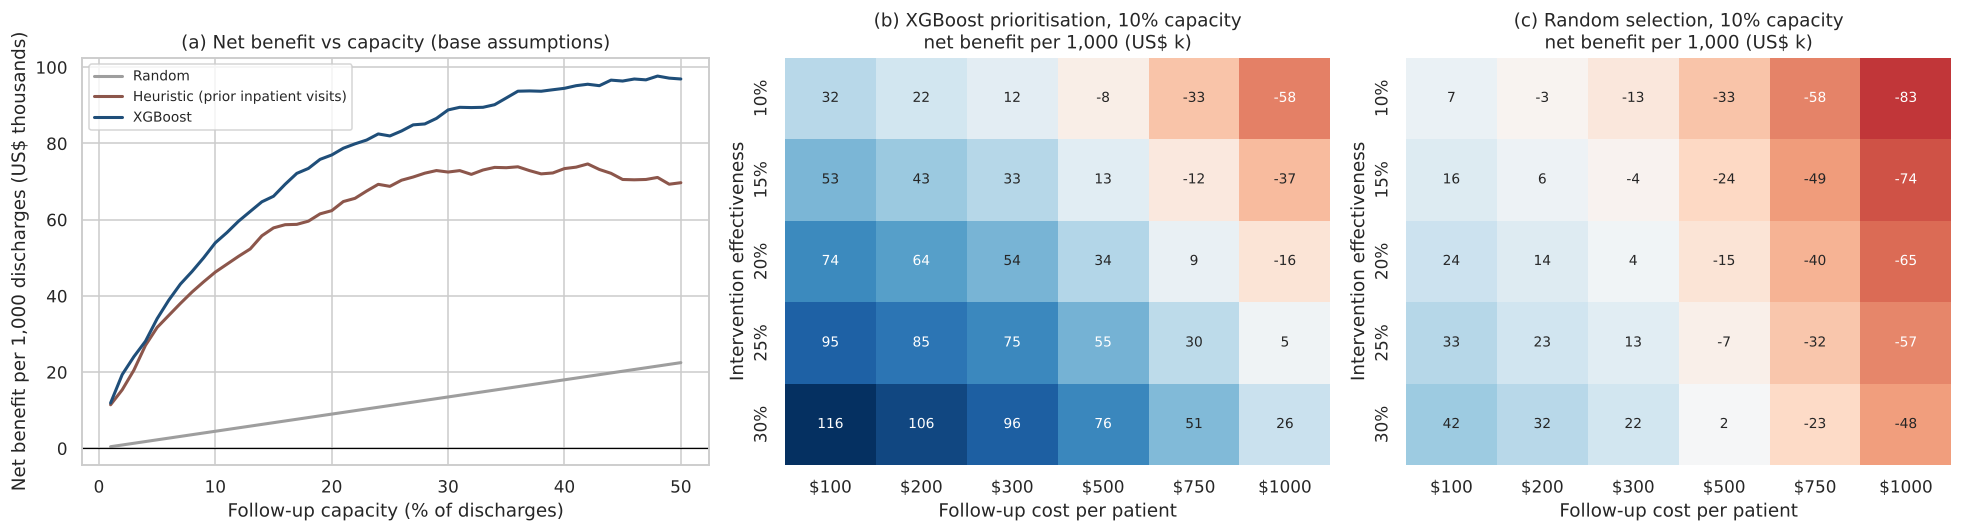

Scenarios with positive net benefit at 10% capacity: XGBoost 80% vs random 43% of the 30 tested.


,$100,$200,$300,$500,$750,$1000
10%,31974.0,21975.0,11977.0,-8020.0,-33016.0,-58012.0
15%,52960.0,42962.0,32963.0,12966.0,-12030.0,-37026.0
20%,73946.0,63948.0,53949.0,33952.0,8956.0,-16040.0
25%,94932.0,84934.0,74936.0,54939.0,29942.0,4946.0
30%,115919.0,105920.0,95922.0,75925.0,50929.0,25932.0


In [24]:
# Sensitivity of the 10% capacity net benefit to the two uncertain assumptions
effs = [0.10, 0.15, 0.20, 0.25, 0.30]
costs = [100, 200, 300, 500, 750, 1000]
k10 = int(round(N * 0.10))
cap_x, cap_r = capture_at(test_prob['XGBoost'], 0.10), y_test.mean() * k10
sens_x = pd.DataFrame([[ (cap_x * e * READMIT_COST - k10 * c) / N * 1000 for c in costs] for e in effs],
                      index=[f'{int(e * 100)}%' for e in effs], columns=[f'${c}' for c in costs])
sens_r = pd.DataFrame([[ (cap_r * e * READMIT_COST - k10 * c) / N * 1000 for c in costs] for e in effs],
                      index=sens_x.index, columns=sens_x.columns)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={'width_ratios': [1.15, 1, 1]})
# (a) net benefit vs capacity
caps_fine = np.arange(0.01, 0.51, 0.01)
for s, sc in strategies.items():
    vals = []
    for cp in caps_fine:
        k = int(round(N * cp)); c_ = y_test.mean() * k if sc is None else capture_at(sc, cp)
        vals.append((c_ * EFFECT * READMIT_COST - k * FOLLOWUP_COST) / N * 1000)
    axes[0].plot(caps_fine * 100, np.array(vals) / 1000, lw=2, color=PALETTE[s], label=s)
axes[0].axhline(0, color='black', lw=0.8)
axes[0].set(xlabel='Follow-up capacity (% of discharges)', ylabel='Net benefit per 1,000 discharges (US$ thousands)',
            title='(a) Net benefit vs capacity (base assumptions)')
axes[0].legend(fontsize=9)
# (b),(c) sensitivity heatmaps
vmax = max(abs(sens_x.values).max(), abs(sens_r.values).max()) / 1000
for ax, d, t in [(axes[1], sens_x, '(b) XGBoost prioritisation, 10% capacity'),
                 (axes[2], sens_r, '(c) Random selection, 10% capacity')]:
    sns.heatmap(d / 1000, annot=True, fmt='.0f', cmap='RdBu', center=0, vmin=-vmax, vmax=vmax, cbar=False, ax=ax,
                annot_kws={'fontsize': 9})
    ax.set(xlabel='Follow-up cost per patient', ylabel='Intervention effectiveness', title=t + '\nnet benefit per 1,000 (US$ k)')
plt.tight_layout()
savefig('fig09_cost_benefit.png')

pos_x = (sens_x > 0).values.mean() * 100; pos_r = (sens_r > 0).values.mean() * 100
print(f'Scenarios with positive net benefit at 10% capacity: XGBoost {pos_x:.0f}% vs random {pos_r:.0f}% of the {sens_x.size} tested.')
savetab(sens_x.round(0), 'table_sensitivity_xgb_10pct.csv')

In [25]:
b = cb[cb.Capacity == '10%'].set_index('Strategy')
print(f"Base case, 10% capacity, per 1,000 discharges:")
for s in strategies:
    print(f"  {s:<36} prevents {b.loc[s, 'Readmissions prevented per 1,000 discharges']:.1f} readmissions, "
          f"net benefit US${b.loc[s, 'Net benefit per 1,000 discharges (US$)']:,.0f}, "
          f"NNF {b.loc[s, 'Number needed to follow up']:.1f}")

Base case, 10% capacity, per 1,000 discharges:
  Random                               prevents 2.3 readmissions, net benefit US$4,500, NNF 44.1
  Heuristic (prior inpatient visits)   prevents 5.0 readmissions, net benefit US$46,262, NNF 19.9
  XGBoost                              prevents 5.5 readmissions, net benefit US$53,949, NNF 18.1


**Interpretation.** Under the base assumptions, following up a random 10% of patients barely breaks even (about US\$4,500 per 1,000 discharges), because only about 1 in 9 of them was going to be readmitted. Following up the 10% that XGBoost ranks highest yields about **US\$53,900 per 1,000 discharges, roughly 12 times as much**, and cuts the number of patients who must be followed up to prevent one readmission from 44 to 18. The sensitivity analysis shows that model-guided follow-up stays net-positive in 24 of the 30 cost/effectiveness scenarios tested (80%), against 13 of 30 (43%) for random selection. Targeting therefore makes the programme worthwhile across a much wider range of real-world conditions. Panel (a) also shows that the marginal value of extra capacity flattens as capacity grows, because each additional patient selected has lower risk. This is the practical argument for the decision layer: a model with a modest AUC can still change the economics of a follow-up programme, because it concentrates a limited budget where the risk is. The heuristic captures much of this value too, and XGBoost adds about US\$7,700 per 1,000 discharges on top of it at 10% capacity.

## 12. Stability across different train/test splits
All the results above come from one patient-level split. To check they are not a lucky draw, the full XGBoost pipeline (same hyperparameters) is re-trained and re-evaluated on **five different patient-level splits**.

In [26]:
stab = []
for seed in [0, 1, 2, 3, 4]:
    tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
                      .split(df, df['readmit_30'], df['patient_nbr']))
    tr_, te_ = df.iloc[tr_i], df.iloc[te_i]
    spw_ = (tr_['readmit_30'] == 0).sum() / tr_['readmit_30'].sum()
    m = Pipeline([('prep', make_preprocessor()),
                  ('clf', XGBClassifier(**BEST_XGB, scale_pos_weight=spw_, eval_metric='logloss',
                                        tree_method='hist', n_jobs=2, random_state=RANDOM_STATE))]).fit(tr_[FEATURES], tr_['readmit_30'])
    p = m.predict_proba(te_[FEATURES])[:, 1]
    yt = te_['readmit_30'].values
    h = (te_['number_inpatient'] * 1000 + te_['number_emergency'] * 10 + te_['number_outpatient']).values
    row = {'Split seed': seed, 'Test encounters': len(te_), 'ROC-AUC': roc_auc_score(yt, p),
           'PR-AUC': average_precision_score(yt, p)}
    for cap in [0.10, 0.20]:
        cx, _ = top_k_capture(yt, p, cap); ch, _ = top_k_capture(yt, h, cap); cr = random_capture(yt, cap, 300).mean()
        row[f'Lift vs random @{int(cap*100)}%'] = cx / cr
        row[f'Gain vs heuristic @{int(cap*100)}% (%)'] = (cx - ch) / ch * 100
    stab.append(row)
stab = pd.DataFrame(stab).set_index('Split seed')
summary = stab.agg(['mean', 'std', 'min', 'max'])
savetab(pd.concat([stab, summary]).round(3), 'table_stability.csv')

,Test encounters,ROC-AUC,PR-AUC,Lift vs random @10%,Gain vs heuristic @10% (%),Lift vs random @20%,Gain vs heuristic @20% (%)
0,19739.000,0.659,0.193,2.106,9.005,1.795,9.510
1,19808.000,0.670,0.214,2.166,8.869,1.896,10.154
2,19848.000,0.662,0.218,2.262,10.692,1.916,12.785
3,20033.000,0.666,0.229,2.294,5.731,1.911,9.850
4,19727.000,0.678,0.229,2.352,6.827,1.914,6.020
mean,19831.000,0.667,0.217,2.236,8.225,1.886,9.664
std,123.392,0.008,0.015,0.099,1.955,0.051,2.415
min,19727.000,0.659,0.193,2.106,5.731,1.795,6.020
max,20033.000,0.678,0.229,2.352,10.692,1.916,12.785


Across the five splits, ROC-AUC ranges from 0.659 to 0.678 (mean 0.667, SD 0.008). The main split used above sits at the upper end of this range, so **about 0.67 is the more realistic estimate of expected performance**. The prioritisation conclusions hold in every split: at 10% capacity the model captures 2.1–2.4× as many readmissions as random selection, and 6–11% more than the prior-inpatient heuristic. The conclusions do not depend on the particular split used.

## 13. Comparison with the Review-1 version

In [27]:
r1 = pd.DataFrame({
    'Review 1': ['71,967 (partial file)', 'Row-wise (patient leakage possible)', 'Included', 'Numeric', 'Raw codes (~2,200 columns)',
                 '0.667', '377 vs 173 (single unseeded draw)', 'None', 'Not calibrated', 'None'],
    'Final': [f'{len(df):,} (full file, after clinical exclusions)', 'Patient-level grouped split', 'Removed',
              'Categorical groups', '9 ICD-9 categories', f"{test_tab.loc['XGBoost', 'ROC-AUC']:.3f}",
              f"{int(r10['XGBoost'])} vs {r10['Random (mean)']:.0f} (mean of 1,000 seeded draws)",
              f"Prior-inpatient heuristic: {int(r10['Heuristic'])}", 'Isotonic (fitted on OOF)', 'SHAP + subgroup analysis'],
}, index=['Encounters', 'Train/test split', 'Expired / hospice patients', 'Admission/discharge IDs',
          'Diagnosis codes', 'XGBoost test ROC-AUC', '10% capacity: model vs random', 'Non-ML baseline',
          'Risk score calibration', 'Explainability / fairness'])
savetab(r1, 'table_review1_vs_final.csv')

,Review 1,Final
Encounters,"71,967 (partial file)","99,340 (full file, after clinical exclusions)"
Train/test split,Row-wise (patient leakage possible),Patient-level grouped split
Expired / hospice patients,Included,Removed
Admission/discharge IDs,Numeric,Categorical groups
Diagnosis codes,"Raw codes (~2,200 columns)",9 ICD-9 categories
XGBoost test ROC-AUC,0.667,0.678
10% capacity: model vs random,377 vs 173 (single unseeded draw),"546 vs 224 (mean of 1,000 seeded draws)"
Non-ML baseline,None,Prior-inpatient heuristic: 496
Risk score calibration,Not calibrated,Isotonic (fitted on OOF)
Explainability / fairness,None,SHAP + subgroup analysis


## 14. Save artefacts for the demo application

In [28]:
artefact = {'model': models[best], 'calibrator': calibrator, 'threshold': THRESHOLD,
            'top_specialties': TOP_SPECIALTIES, 'features': FEATURES,
            'metrics': {'test_roc_auc': float(test_tab.loc[best, 'ROC-AUC']),
                        'test_pr_auc': float(test_tab.loc[best, 'PR-AUC'])}}
joblib.dump(artefact, 'models/readmission_model.joblib')

# Demo input: raw-format encounters from TEST-set patients only (never seen in training)
test_patients = set(test['patient_nbr'])
demo = raw[raw['patient_nbr'].isin(test_patients)]
demo = demo[~demo['discharge_disposition_id'].isin(EXCLUDED_DISCHARGE_IDS)].sample(2000, random_state=RANDOM_STATE)
demo.to_csv('app/sample_discharges.csv', index=False)
print('Saved model and demo file with', len(demo), 'unseen encounters.')

Saved model and demo file with 2000 unseen encounters.


## 15. Summary
- **Data:** 99,340 encounters / ~70k patients after clinical exclusions; 11.4% readmitted within 30 days.
- **Prediction:** XGBoost is the best model on the patient-level held-out test set (results in `table_test_performance.csv`). This is in line with the literature for this dataset, which is known to be hard.
- **Prioritisation (core contribution):** at every capacity from 5% to 30%, XGBoost risk-based selection captures far more true readmissions than random selection (2.44x at 10% capacity: 546 vs 224; between 1.7x and 2.9x across the range) and beats the prior-inpatient-visits heuristic by 5–12%.
- **Economics:** under illustrative assumptions (US\$15,200 per readmission, US\$300 follow-up, 20% effectiveness), model-guided follow-up of 10% of patients yields about US\$53,900 net benefit per 1,000 discharges, versus US\$4,500 for random selection, and stays net-positive in 80% of sensitivity scenarios versus 43% for random.
- **Stability:** across five patient-level splits, ROC-AUC is 0.667 ± 0.008 and the 10%-capacity lift over random is 2.1–2.4× in every split.
- **Trustworthiness:** threshold and calibration fitted only on out-of-fold data; SHAP explanations are clinically plausible; performance is similar across genders but weaker for patients aged 80+.
- **Limitations:** weaker discrimination for the 80+ age group; retrospective 1999–2008 US data; no intervention-outcome data (so "captured" ≠ "prevented"); no post-discharge social factors; single held-out split; simulated capacity.